### scrape data

In [ ]:
import time, re
import requests
from bs4 import BeautifulSoup

headers = {"User-Agent": "Mozilla/5.0", "Accept-Language": "en-US,en;q=0.9"}
base = "https://www.transfermarkt.com"

search_urls = [
    f"{base}/detailsuche/spielerdetail/suche/65432453",
    f"{base}/detailsuche/spielerdetail/suche/65432456",
    f"{base}/detailsuche/spielerdetail/suche/65432460",
    f"{base}/detailsuche/spielerdetail/suche/65432465",
    f"{base}/detailsuche/spielerdetail/suche/65432466",
    f"{base}/detailsuche/spielerdetail/suche/65432471",
]

players = {}

for s_idx, search_url in enumerate(search_urls, 1):
    for page in range(1, 50):
        url = search_url if page == 1 else f"{search_url}?page={page}"
        r = requests.get(url, headers=headers)
        time.sleep(2)
        if r.status_code != 200:
            break

        soup = BeautifulSoup(r.text, "html.parser")
        before = len(players)
        for a in soup.select("table.items td.hauptlink a[href*='/profil/spieler/']"):
            m = re.search(r"/profil/spieler/(\d+)", a["href"])
            if m:
                players[m.group(1)] = base + a["href"]

        print(f"search {s_idx}/{len(search_urls)} | page {page} | {len(players)} players".ljust(70), end="\r")
        if len(players) == before:
            break

print(f"\n{len(players)} players")
print(list(players.items())[:3])

In [ ]:
import time, json, os, random
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.edge.options import Options

out_file = "players_market_value.jsonl"
done = set()
if os.path.exists(out_file):
    with open(out_file, encoding="utf-8") as fh:
        done = {r["player_id"] for r in map(json.loads, fh) if r.get("market_value")}

todo = [(pid, url) for pid, url in players.items() if str(pid) not in done and str(pid).isdigit()]

options = Options()
options.page_load_strategy = "eager"
driver = webdriver.Edge(options=options)

for i, (pid, url) in enumerate(todo, 1):
    print(f"[{i}/{len(todo)}] {pid}".ljust(70), end="\r")
    driver.get(f"https://www.transfermarkt.com/ceapi/marketValueDevelopment/graph/{pid}")

    market_value = []
    start = time.time()
    while time.time() - start < 600:
        try:
            text = driver.find_element(By.TAG_NAME, "body").text
            market_value = json.loads(text)["list"]
            break
        except Exception:
            time.sleep(2)

    with open(out_file, "a", encoding="utf-8") as fh:
        fh.write(json.dumps({"player_id": str(pid), "player_url": url, "market_value": market_value}, ensure_ascii=False) + "\n")

    time.sleep(random.uniform(1, 3))

driver.quit()
print("\nfinished")

In [14]:
import json

with open("players_market_value.jsonl", encoding="utf-8") as f:
    data = [json.loads(line) for line in f]

with open("players_market_value.json", "w", encoding="utf-8") as f:
    json.dump(data, f, ensure_ascii=False, indent=2)

### analysis

In [1]:
import pandas as pd
pd.options.display.max_columns=100

import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
import json
import seaborn
plt.style.use('ggplot')

In [2]:

with open('players_market_value.json', 'r', encoding='utf-8') as f:
    data = json.load(f)

In [3]:
json=data[0]

In [4]:
json

{'player_id': '418560',
 'player_url': 'https://www.transfermarkt.com/erling-haaland/profil/spieler/418560',
 'market_value': [{'x': 1482015600000,
   'y': 200000,
   'mw': '€200k',
   'datum_mw': '18/12/2016',
   'verein': 'Bryne FK',
   'age': '16',
   'wappen': 'https://img.a.transfermarkt.technology/wappen/profil/1057.png?lm=1789459228'},
  {'x': 1513983600000,
   'y': 300000,
   'mw': '€300k',
   'datum_mw': '23/12/2017',
   'verein': 'Molde FK',
   'age': '17',
   'wappen': 'https://img.a.transfermarkt.technology/wappen/profil/687.png?lm=1789459206'},
  {'x': 1536530400000,
   'y': 2000000,
   'mw': '€2.00m',
   'datum_mw': '10/09/2018',
   'verein': 'Molde FK',
   'age': '18',
   'wappen': ''},
  {'x': 1546124400000,
   'y': 5000000,
   'mw': '€5.00m',
   'datum_mw': '30/12/2018',
   'verein': 'Molde FK',
   'age': '18',
   'wappen': ''},
  {'x': 1559512800000,
   'y': 5000000,
   'mw': '€5.00m',
   'datum_mw': '03/06/2019',
   'verein': 'Red Bull Salzburg',
   'age': '18',
   '

In [5]:
mw_dict={}
for json in data:
    player_id=json['player_id']
    dict_={e['age']:e['mw'] for e in json['market_value']}
    mw_dict[player_id]=dict_

In [6]:
mw_df = pd.DataFrame(
    [{"player_id": rec["player_id"], "age": e["age"], "market_value": e["mw"]}
     for rec in data for e in rec["market_value"]]
)

In [7]:
mw_df["market_value"] = (mw_df["market_value"].astype(str)
    .str.replace("€", "", regex=False)
    .str.replace("k", "e3", regex=False)
    .str.replace("m", "e6", regex=False)
    .str.replace("bn", "e9", regex=False)
    .pipe(pd.to_numeric, errors="coerce"))

In [8]:
mw_df

,player_id,age,market_value
0,418560,16,200000.0
1,418560,17,300000.0
2,418560,18,2000000.0
3,418560,18,5000000.0
4,418560,18,5000000.0
...,...,...,...
40663,155555,35,100000.0
40664,155555,35,100000.0
40665,155555,36,100000.0
40666,155555,36,100000.0


Text(0.5, 1.0, 'average market value by age')

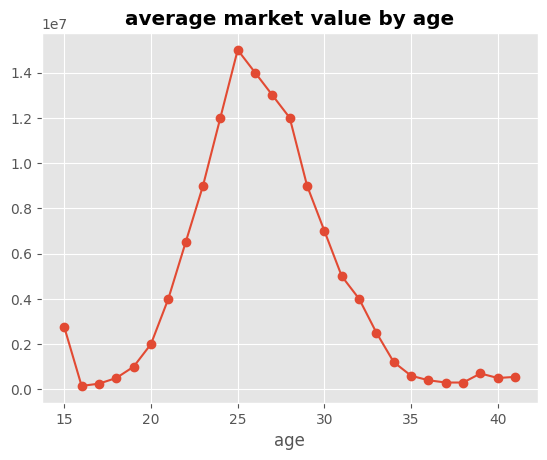

In [9]:
curve = mw_df.groupby("age")["market_value"].agg(["mean", "median", "count"])
curve["median"].plot(marker="o")
plt.title('average market value by age', fontweight='bold')

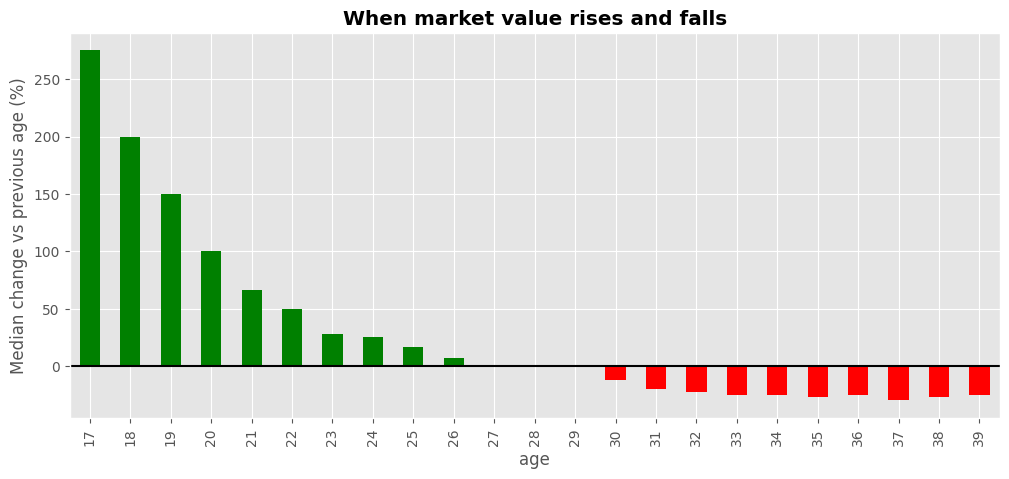

In [10]:

yearly = mw_df.groupby(["player_id", "age"])["market_value"].max().reset_index().sort_values(["player_id", "age"])
yearly["change"] = yearly.groupby("player_id")["market_value"].pct_change() * 100

by_age = yearly.groupby("age")["change"].agg(median="median", players="count", rising=lambda s: (s > 0).mean() * 100)
by_age = by_age[by_age["players"] >= 30]                     # skip ages with too few players

colors = ["green" if v > 0 else "red" for v in by_age["median"]]
by_age["median"].plot(kind="bar", color=colors, figsize=(12, 5))
plt.axhline(0, color="black")
plt.ylabel("Median change vs previous age (%)")
plt.title("When market value rises and falls", fontweight='bold')
plt.show()